<a href="https://colab.research.google.com/github/zahraagustina34rpl-wq/PraktikumAVD/blob/main/Praktikum_AVD.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# LATIHAN 1

import pandas as pd
df = pd.read_csv('penjualan_nusantaramart.csv')
print(df.head()) # lihat 5 baris pertama
print(df.info()) # tipe data & jumlah data kosong
print(df.describe()) # ringkasan statistik

# rata-rata total pembelian per kategori produk
rata_kategori = df.groupby('kategori_produk')['total'].mean()
print(rata_kategori.sort_values(ascending=False))

   order_id     tanggal    kategori_produk        nama_produk   wilayah  \
0      1146  2026-01-03           Olahraga        Matras Yoga    Malang   
1      1166  2026-01-05            Fashion       Celana Jeans  Surabaya   
2      1190  2026-01-05          Kesehatan   Masker Medis Box  Semarang   
3      1219  2026-01-08  Makanan & Minuman  Kopi Kemasan 200g   Bandung   
4      1133  2026-01-10            Fashion         Tas Ransel  Surabaya   

   jumlah  harga_satuan   total metode_pembayaran  rating_pelanggan  
0       5         90000  450000          E-Wallet                 4  
1       5        175000  875000     Transfer Bank                 5  
2       4         30000  120000      Kartu Kredit                 3  
3       4         28000  112000          E-Wallet                 3  
4       4        130000  520000      Kartu Kredit                 4  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 220 entries, 0 to 219
Data columns (total 10 columns):
 #   Column             

*   Kategori produk yang memiliki rata-rata nilai transaksi tertiggi adalah **Elektronik** dengan nilai Rp363.541,67
*   Tidak ada data kosong pada dataset ini. Cara mengeceknya yaitu dengan melihat bagian RangeIndex yang menunjukkan total data sebanyak 220 baris, lalu membandingkannya dengan kolom Non-Null Count pada df.info(). Karena seluruh 10 kolom mencantumkan angka 220 non-null, artinya semua baris pada setiap kolom terisi penuh tanpa ada data yang hilang.
*   Nilai mean pada kolom total adalah Rp238.486,4 sedangkan nilai Median (50%) adalah Rp125.000. Karena nilai Mean jauh lebih besar daripada Median, sebaran data transaksi bersifat miring ke kanan (right-skewed). Hal ini menunjukkan bahwa mayoritas transaksi bernilai kecil hingga menengah (sekitar Rp125.000 atau kurang), tetapi terdapat beberapa transaksi dengan nilai sangat besar (nilai maksimum mencapai Rp3.400.000) yang membuat nilai rata-rata tertarik menjadi lebih tinggi.

/tmp/ipykernel_1449/3884287079.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=total_kategori.values, y=total_kategori.index, palette='Blues_r')


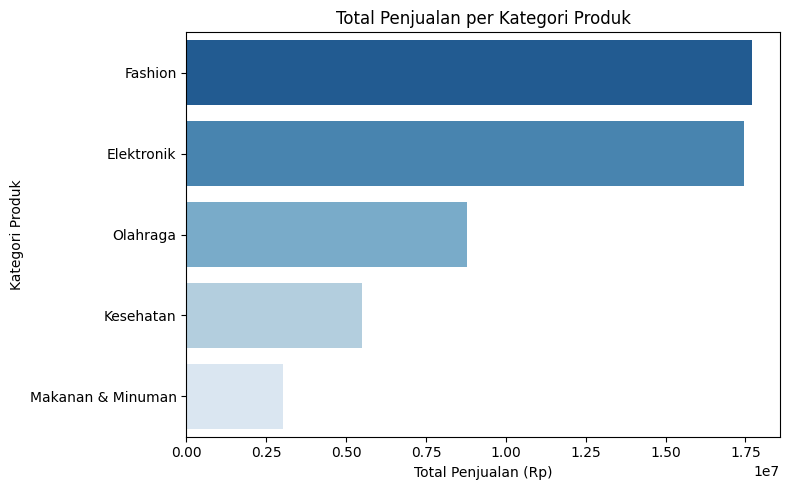

In [2]:
# LATIHAN 2

import matplotlib.pyplot as plt
import seaborn as sns

total_kategori = df.groupby('kategori_produk')['total'].sum().sort_values(ascending=False)

plt.figure(figsize=(8,5))
sns.barplot(x=total_kategori.values, y=total_kategori.index, palette='Blues_r')
plt.title('Total Penjualan per Kategori Produk')
plt.xlabel('Total Penjualan (Rp)')
plt.ylabel('Kategori Produk')
plt.tight_layout()
plt.show()

*   Kategori yang menyumbang penjualan tertinggi yaitu **Fashion**, sedangkan kategori yang menyumbang penjualan terendah yaitu **Makanan & Minuman**
*   Berdasarkan hasil analisis grafik, rekomendasi bisnis yang dapat diberikan kepada manager Nusantara Mart untuk menjaga ketersediaan stok pada kategori Fashion dan Elektronik agar tidak terjadi kelangkaan barang, serta menjadikannya produk unggulan dalam promosi utama. Untuk kategori Makanan & Minuman, manager disarankan menerapkan strategi paket bundling bersama produk terlaris, memberikan diskon khusus, dan mengevaluasi variasi produk guna meningkatkan angka penjualan.

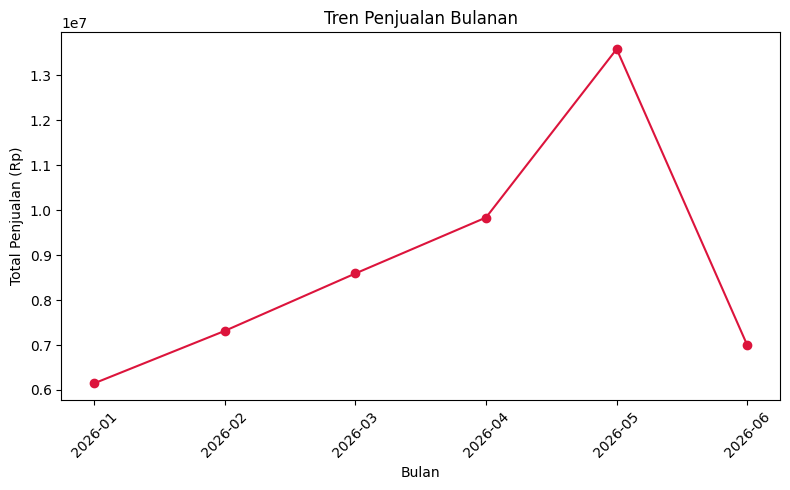

In [3]:
# LATIHAN 3

df['tanggal'] = pd.to_datetime(df['tanggal'])
df['bulan'] = df['tanggal'].dt.to_period('M')

tren_bulanan = df.groupby('bulan')['total'].sum()

plt.figure(figsize=(8,5))
plt.plot(tren_bulanan.index.astype(str), tren_bulanan.values, marker='o', color='crimson')
plt.title('Tren Penjualan Bulanan')
plt.xlabel('Bulan')
plt.ylabel('Total Penjualan (Rp)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

*   Bulan yang memiliki tingkat penjualan tertinggi adalah Mei 2026 (2026-05) dengan total penjualan mencapai lebih dari Rp13,5 juta. Lonjakan ini kemungkinan besar disebabkan oleh momentum libur panjang pertengahan tahun, diskon besar-besaran, maupun kebutuhan belanja konsumen yang sedang meningkat di bulan tersebut.
*   Secara keseluruhan, pola tren penjualan Nusantara Mart cenderung fluktuatif dengan kecenderungan naik pada awal periode lalu turun tajam di akhir. Hal ini terlihat dari garis grafik yang konsisten meningkat sejak Januari hingga Mei 2026, namun kemudian mengalami penurunan drastis pada bulan Juni 2026.

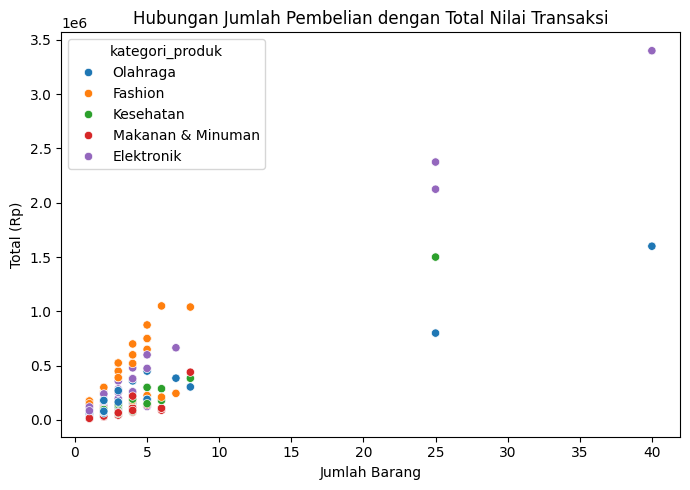

In [4]:
# LATIHAN 4

plt.figure(figsize=(7,5))
sns.scatterplot(data=df, x='jumlah', y='total', hue='kategori_produk')
plt.title('Hubungan Jumlah Pembelian dengan Total Nilai Transaksi')
plt.xlabel('Jumlah Barang')
plt.ylabel('Total (Rp)')
plt.tight_layout()
plt.show()

*   Terlihat pola hubungan positif. Artinya, semakin banyak jumlah barang yang dibeli, semakin tinggi total nilai transaksinya.
*   Ada. Titik data yang terpisah jauh dari pola umum berasal dari kategori Elektronik, Kesehatan, dan Olahraga.

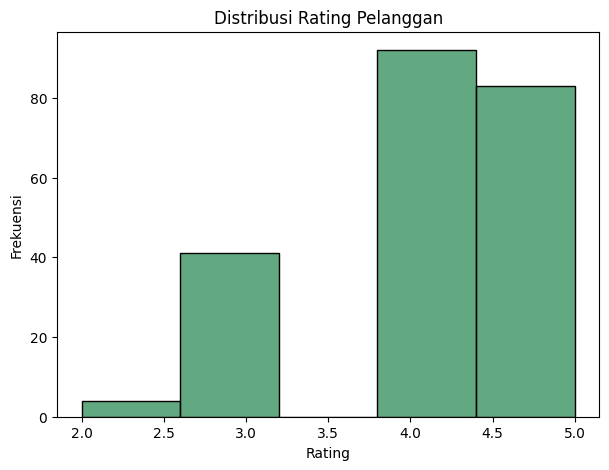

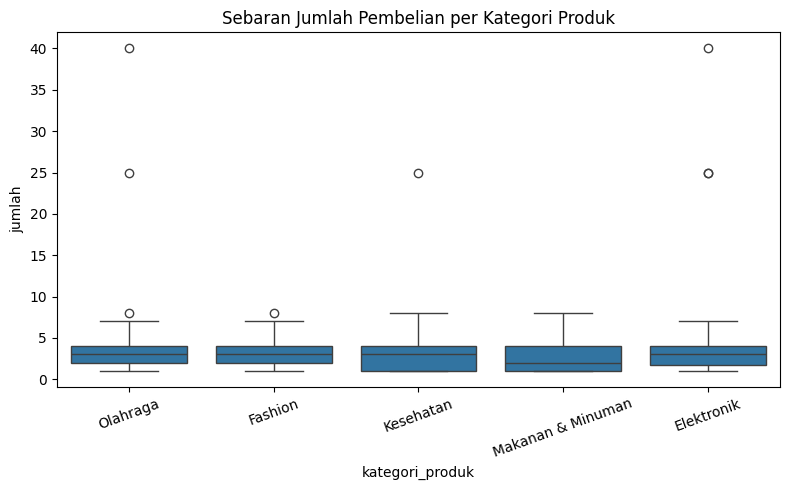

In [5]:
# LATIHAN 5

# Histogram distribusi rating pelanggan
plt.figure(figsize=(7,5))
sns.histplot(df['rating_pelanggan'], bins=5, color='seagreen')
plt.title('Distribusi Rating Pelanggan')
plt.xlabel('Rating')
plt.ylabel('Frekuensi')
plt.show()

# Boxplot jumlah pembelian per kategori (deteksi outlier)
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x='kategori_produk', y='jumlah')
plt.title('Sebaran Jumlah Pembelian per Kategori Produk')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

*   Distribusi rating pelanggan cenderung tinggi. Mayoritas pelanggan memberikan rating bernilai tinggi (rating 4 dan 5), yang menunjukkan tingkat kepuasan pelanggan secara keseluruhan sangat baik.
*   Berdasarkan grafik boxplot, kategori produk yang memiliki titik-titik di luar kotak boxplot (outlier) yaitu Olahraga, Fashion, Kesehatan, dan Elektronik. Hal ini kemungkinan besar disebabkan adanya transaksi pembelian barang dalam kuantitas yang sangat banyak sekaligus.

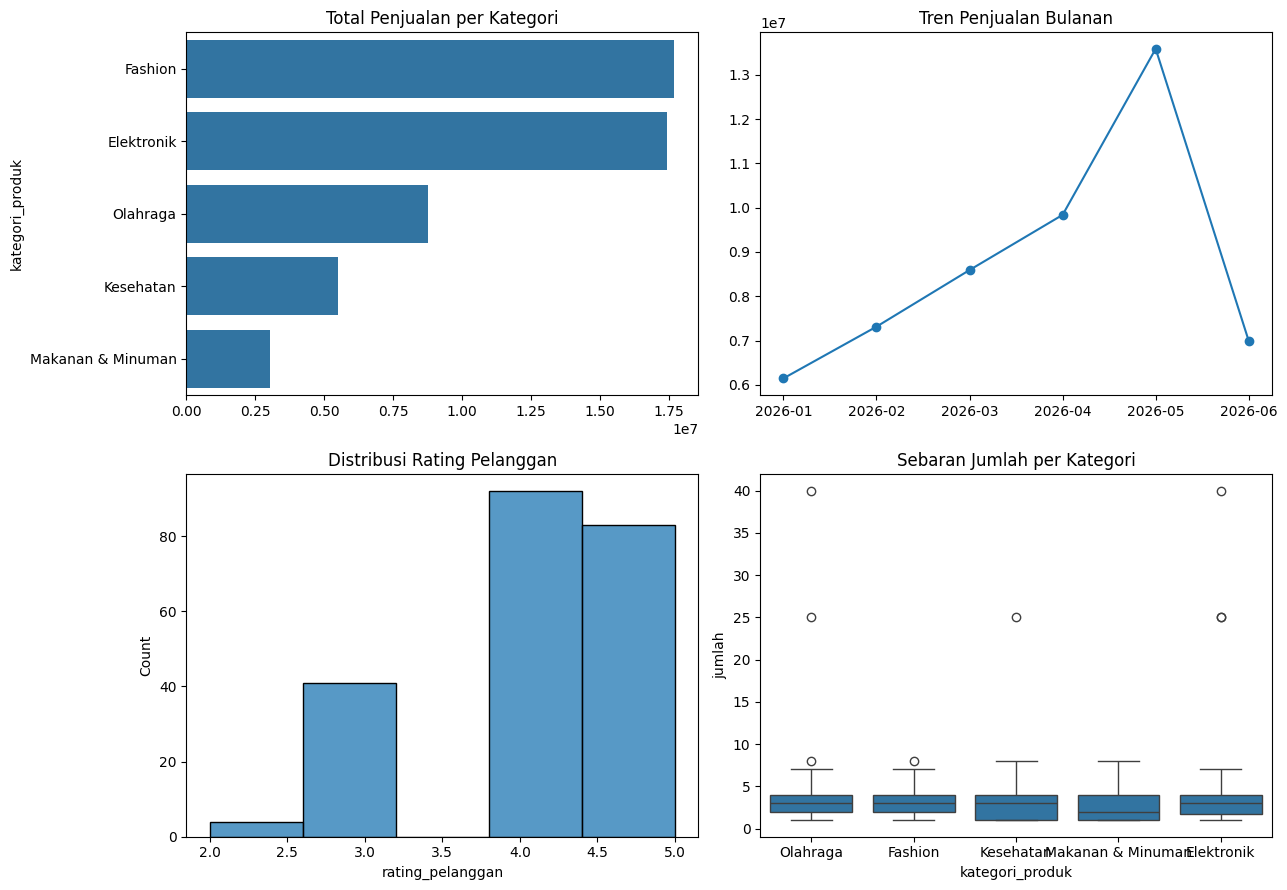

In [6]:
# LATIHAN 6

fig, axes = plt.subplots(2, 2, figsize=(13,9))

sns.barplot(x=total_kategori.values, y=total_kategori.index, ax=axes[0,0])
axes[0,0].set_title('Total Penjualan per Kategori')

axes[0,1].plot(tren_bulanan.index.astype(str), tren_bulanan.values, marker='o')
axes[0,1].set_title('Tren Penjualan Bulanan')

sns.histplot(df['rating_pelanggan'], bins=5, ax=axes[1,0])
axes[1,0].set_title('Distribusi Rating Pelanggan')

sns.boxplot(data=df, x='kategori_produk', y='jumlah', ax=axes[1,1])
axes[1,1].set_title('Sebaran Jumlah per Kategori')

plt.tight_layout()
plt.show()

*   Keuntungannya adalah memudahkan pengambil keputusan melihat seluruh performa bisnis secara ringkas, efisien, dan menyeluruh dalam satu layar tanpa perlu berpindah-pindah dokumen.
*   Sebagai manager, saya akan memprioritaskan penyediaan stok pada kategori Fashion dan Elektronik menjelang bulan puncak penjualan (Mei), membuat program/harga khusus reseller untuk menangani transaksi kuantitas tinggi (outlier), serta menerapkan strategi bundling untuk meningkatkan penjualan kategori Makanan & Minuman.

          id                                    url  \
0  tt0111161  https://www.imdb.com/title/tt0111161/   
1  tt0068646  https://www.imdb.com/title/tt0068646/   
2  tt0468569  https://www.imdb.com/title/tt0468569/   
3  tt0071562  https://www.imdb.com/title/tt0071562/   
4  tt0167260  https://www.imdb.com/title/tt0167260/   

                                    primaryTitle  \
0                       The Shawshank Redemption   
1                                  The Godfather   
2                                The Dark Knight   
3                          The Godfather Part II   
4  The Lord of the Rings: The Return of the King   

                                   originalTitle   type  parentImdbId  \
0                       The Shawshank Redemption  movie           NaN   
1                                  The Godfather  movie           NaN   
2                                The Dark Knight  movie           NaN   
3                          The Godfather Part II  movie         

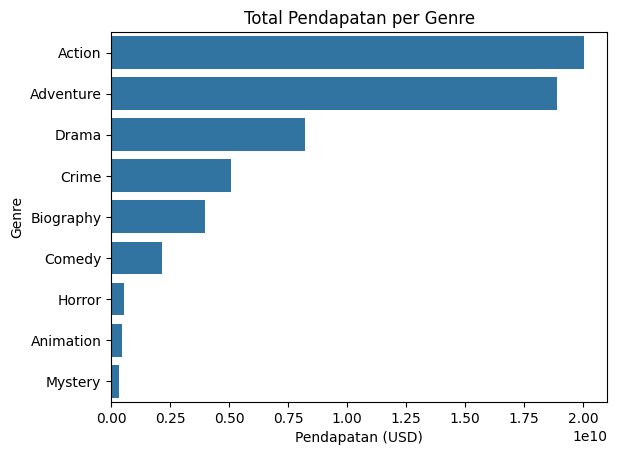

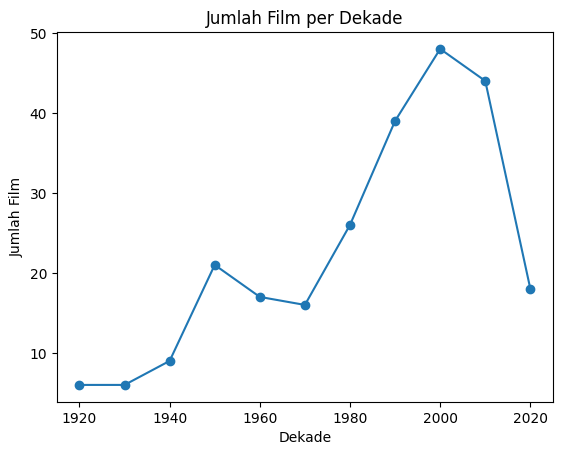

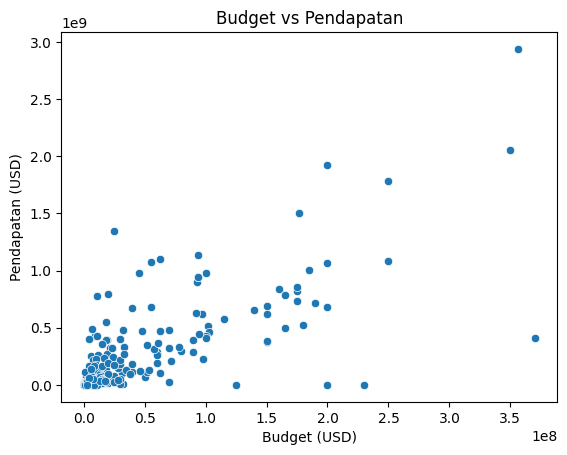

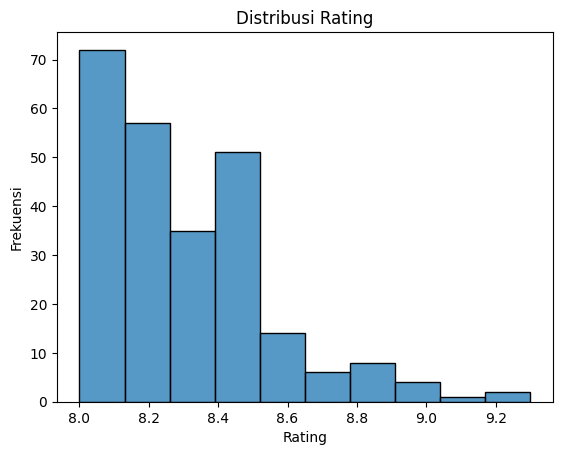

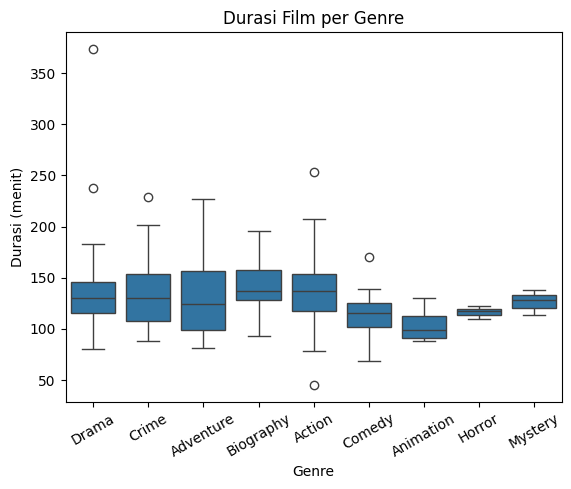

                           primaryTitle  runtimeMinutes
23                        Seven Samurai             207
33   Kill Bill: The Whole Bloody Affair             253
90          Once Upon a Time in America             229
101                  Lawrence of Arabia             227
169                  Gone with the Wind             238
176                   The Best of Youth             374
183                             Ben-Hur             212
212                        Sherlock Jr.              45


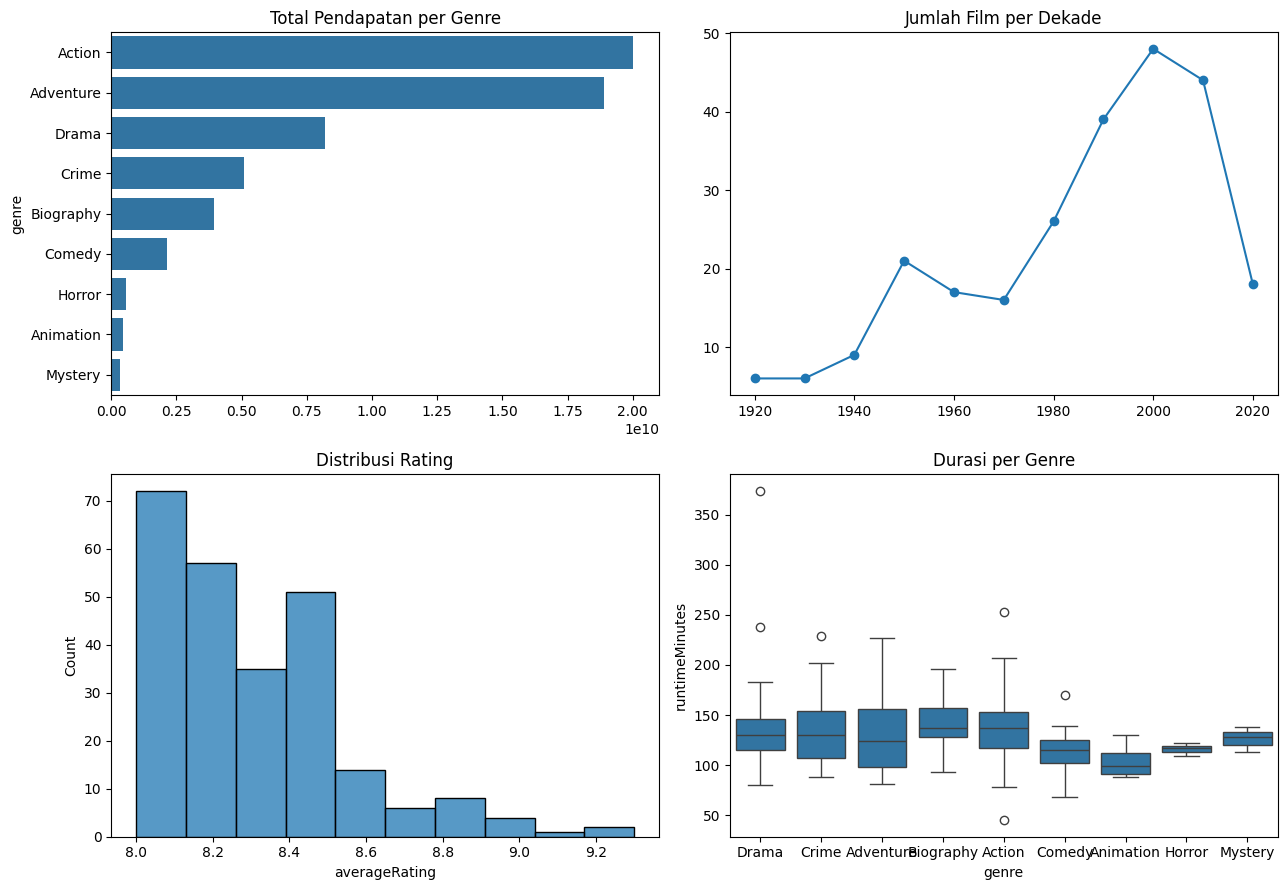

In [7]:
# TUGAS KELOMPOK

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Baca & eksplorasi data
df = pd.read_csv('imdb_top_250_movies.csv')
print(df.head())
print(df.info())
print(df.describe())
print(df.isnull().sum())
print('Duplikat:', df.duplicated().sum())

# ambil genre pertama saja, contoh "['Crime', 'Thriller']" -> "Crime"
df['genre'] = df['genres'].str.split("'").str[1]

# statistik pendapatan
print('Mean  :', df['grossWorldwide'].mean())
print('Median:', df['grossWorldwide'].median())
print('Std   :', df['grossWorldwide'].std())
print(df.groupby('genre')['grossWorldwide'].mean().sort_values(ascending=False))

# 2. Bar chart: total pendapatan per genre
total = df.groupby('genre')['grossWorldwide'].sum().sort_values(ascending=False)
sns.barplot(x=total.values, y=total.index)
plt.title('Total Pendapatan per Genre')
plt.xlabel('Pendapatan (USD)')
plt.ylabel('Genre')
plt.show()

# 3. Line chart: jumlah film per dekade
df['dekade'] = df['startYear'] // 10 * 10
tren = df.groupby('dekade')['id'].count()
plt.plot(tren.index, tren.values, marker='o')
plt.title('Jumlah Film per Dekade')
plt.xlabel('Dekade')
plt.ylabel('Jumlah Film')
plt.show()

# 4. Scatter plot: budget vs pendapatan (budget > 400 juta dibuang karena mata uang lokal)
data = df[df['budget'] <= 400000000]
sns.scatterplot(data=data, x='budget', y='grossWorldwide')
plt.title('Budget vs Pendapatan')
plt.xlabel('Budget (USD)')
plt.ylabel('Pendapatan (USD)')
plt.show()

# 5. Histogram rating & boxplot durasi
sns.histplot(df['averageRating'], bins=10)
plt.title('Distribusi Rating')
plt.xlabel('Rating')
plt.ylabel('Frekuensi')
plt.show()

sns.boxplot(data=df, x='genre', y='runtimeMinutes')
plt.title('Durasi Film per Genre')
plt.xlabel('Genre')
plt.ylabel('Durasi (menit)')
plt.xticks(rotation=30)
plt.show()

# outlier durasi (aturan IQR)
q1 = df['runtimeMinutes'].quantile(0.25)
q3 = df['runtimeMinutes'].quantile(0.75)
iqr = q3 - q1
outlier = df[(df['runtimeMinutes'] < q1 - 1.5 * iqr) | (df['runtimeMinutes'] > q3 + 1.5 * iqr)]
print(outlier[['primaryTitle', 'runtimeMinutes']])

# 6. Dashboard
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
sns.barplot(x=total.values, y=total.index, ax=axes[0, 0])
axes[0, 0].set_title('Total Pendapatan per Genre')
axes[0, 1].plot(tren.index, tren.values, marker='o')
axes[0, 1].set_title('Jumlah Film per Dekade')
sns.histplot(df['averageRating'], bins=10, ax=axes[1, 0])
axes[1, 0].set_title('Distribusi Rating')
sns.boxplot(data=df, x='genre', y='runtimeMinutes', ax=axes[1, 1])
axes[1, 1].set_title('Durasi per Genre')
plt.tight_layout()
plt.show()

# 7. Laporan (format sesuai modul)
df['negara'] = df['countriesOfOrigin'].str.split("'").str[1]
negara = df.groupby('negara')['grossWorldwide'].sum().sort_values(ascending=False)
terlaris = df.loc[df['grossWorldwide'].idxmax()]
jumlah_genre = df['genre'].value_counts()
dekade_top = df.groupby('dekade')['grossWorldwide'].sum().idxmax()
korelasi = data['budget'].corr(data['grossWorldwide'])

# Analisis Data IMDb Top 250 Movies

Proyek praktikum **Analisis dan Visualisasi Data (AVD)** untuk Kelas XI RPL.
Dataset 250 film IMDb dianalisis dengan Python (Pandas, Matplotlib, Seaborn) untuk mencari film dan genre apa yang paling menguntungkan, lalu hasilnya dipresentasikan dalam bentuk PPT.

## Isi Proyek

| File | Keterangan |
|------|------------|
| `imdb_top_250_movies.csv` | Dataset (250 film, 28 kolom) |
| `imdb_simpel2.py` | Kode analisis: eksplorasi, statistik, grafik, outlier, dashboard, laporan |
| `grafik.py` | Kode untuk menyimpan grafik sebagai gambar (folder `img/`) untuk PPT |
| `IMDb_Top250_Presentasi.pptx` | Slide presentasi (12 slide) |

## Cara Menjalankan

1. Pastikan Python 3 sudah terpasang, lalu pasang library:
   ```bash
   pip install pandas matplotlib seaborn
   ```
2. Taruh semua file dalam satu folder.
3. Jalankan analisis (grafik akan muncul satu per satu):
   ```bash
   python imdb_simpel2.py
   ```
4. Untuk menyimpan grafik menjadi gambar PNG:
   ```bash
   mkdir img
   python grafik.py
   ```

## Alur Analisis

1. **Eksplorasi data:** `head`, `info`, `describe`, cek data kosong dan duplikat.
2. **Statistik deskriptif:** mean, median, standar deviasi, kuartil, dan rata-rata pendapatan per genre.
3. **Visualisasi (5 jenis):**
   - Bar chart: total pendapatan per genre
   - Line chart: jumlah film per dekade
   - Scatter plot: budget vs pendapatan
   - Histogram: distribusi rating
   - Boxplot: durasi film per genre
4. **Deteksi outlier:** aturan IQR pada kolom durasi (`runtimeMinutes`).
5. **Dashboard:** 4 grafik dalam satu figure (subplot 2x2).
6. **Laporan:** ringkasan statistik, temuan, outlier, dan rekomendasi (tercetak di terminal).

## Catatan Data

- Tidak ada data duplikat.
- Data kosong: `budget` (22), `grossWorldwide` (4), `metascore` (20).
- Genre utama diambil dari genre pertama di kolom `genres`.
- Beberapa film non-Hollywood memiliki budget dalam mata uang lokal (contoh: *Life Is Beautiful* = 15 miliar lira), sehingga pada scatter plot film dengan budget di atas USD 400 juta tidak diikutkan.

## Hasil Utama

| Statistik | Nilai |
|-----------|-------|
| Total pendapatan dunia | USD 59,7 miliar |
| Rata-rata pendapatan | USD 242,6 juta |
| Median pendapatan | USD 65,1 juta |
| Genre dengan pendapatan terbesar | Action (USD 20,0 miliar), disusul Adventure (USD 18,9 miliar) |
| Genre dengan film terbanyak | Drama (69 film) |
| Rating rata-rata | 8,31 / 10 |
| Korelasi budget dan pendapatan | 0,74 (positif kuat) |
| Dekade pendapatan tertinggi | 2010-an |

**Insight singkat**

- Mean jauh di atas median, jadi sebaran pendapatan condong ke kanan karena segelintir film blockbuster.
- Action dan Adventure menyumbang sekitar 65% total pendapatan, walaupun film terbanyak ada di genre Drama.
- Semua film berating minimal 8,0 (karena dataset Top 250).

## Outlier

Ada **8 film** dengan durasi di luar batas IQR (batas wajar 52–207 menit), antara lain:

| Film | Durasi (menit) | Dugaan penyebab |
|------|----------------|-----------------|
| The Best of Youth | 374 | Miniseri TV dirilis sebagai film |
| Kill Bill: The Whole Bloody Affair | 253 | Gabungan dua film |
| Gone with the Wind | 238 | Film epik klasik |
| Sherlock Jr. | 45 | Film bisu, sangat pendek |

Pada kolom pendapatan juga ada 20 film outlier (di atas sekitar USD 818 juta), dipimpin *Avengers: Endgame*.

## Rekomendasi Bisnis

1. Prioritaskan produksi genre **Action dan Adventure** untuk pendapatan tinggi.
2. Pertahankan film **Drama** berkualitas untuk menjaga rating dan reputasi.
3. Film berbudget besar perlu **rencana distribusi global**.
4. Gunakan durasi sekitar **110–149 menit** (rentang Q1–Q3).

Nama Anggota Kelompok:
1. Dwi Nuraini Juwita (10)
2. Faqihudin Musyaffa (11)
3. Satrya Khanza Alfaruq Kurniawan (25)
4. Zahra Aurel Agustina (28)